In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/perishable_goods_management.csv")

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (100000, 42)

Column Names:
['record_id', 'product_id', 'product_name', 'category', 'store_id', 'region', 'supplier_id', 'transaction_date', 'expiration_date', 'shelf_life_days', 'days_remaining_at_purchase', 'storage_temp', 'temp_deviation', 'base_price', 'cost_price', 'initial_quantity', 'spoilage_sensitivity', 'day_of_week', 'is_weekend', 'month', 'daily_demand', 'demand_variability', 'temp_abuse_events', 'distribution_hours', 'handling_score', 'packaging_score', 'spoilage_risk', 'was_spoiled', 'quality_grade', 'days_until_expiry', 'markdown_applied', 'discount_pct', 'selling_price', 'units_sold', 'units_wasted', 'waste_pct', 'revenue', 'waste_cost', 'profit', 'profit_margin_pct', 'supplier_score', 'is_promoted']

First 5 Rows:


,record_id,product_id,product_name,category,store_id,region,supplier_id,transaction_date,expiration_date,shelf_life_days,...,selling_price,units_sold,units_wasted,waste_pct,revenue,waste_cost,profit,profit_margin_pct,supplier_score,is_promoted
0,1,BAK_DON_743,Donuts,Bakery,STORE_046,West,SUPPLIER_03,25-09-2024,29-09-2024,4,...,2.60,138,20,12.7,358.80,24.40,166.04,46.3,9,0
1,2,MEA_SAU_338,Sausages,Meat,STORE_030,Southwest,SUPPLIER_12,14-04-2023,21-04-2023,9,...,8.25,251,102,28.9,2070.75,426.36,595.21,28.7,6,0
2,3,BAK_BAG_799,Bagels,Bakery,STORE_035,Midwest,SUPPLIER_08,25-10-2024,27-10-2024,2,...,1.28,483,0,0.0,618.24,0.00,-405.72,-65.6,9,0
3,4,PHA_VAC_801,Vaccines,Pharmaceuticals,STORE_003,Midwest,SUPPLIER_11,29-11-2023,17-02-2024,87,...,209.56,477,0,0.0,99960.12,0.00,57988.89,58.0,6,0
4,5,REA_FRE_422,Fresh Pasta,Ready_to_Eat,STORE_042,West,SUPPLIER_15,06-08-2023,09-08-2023,4,...,5.28,391,0,0.0,2064.48,0.00,879.75,42.6,6,0


In [5]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Data Types:
record_id                       int64
product_id                        str
product_name                      str
category                          str
store_id                          str
region                            str
supplier_id                       str
transaction_date                  str
expiration_date                   str
shelf_life_days                 int64
days_remaining_at_purchase      int64
storage_temp                  float64
temp_deviation                float64
base_price                    float64
cost_price                    float64
initial_quantity                int64
spoilage_sensitivity          float64
day_of_week                     int64
is_weekend                      int64
month                           int64
daily_demand                    int64
demand_variability            float64
temp_abuse_events               int64
distribution_hours            float64
handling_score                  int64
packaging_score                 int64


In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
record_id,100000.0,50000.500000,28867.657797,1.000,25000.750,50000.500,75000.2500,100000.000
shelf_life_days,100000.0,67.169300,140.550322,1.000,5.000,9.000,24.0000,730.000
days_remaining_at_purchase,100000.0,56.114940,118.160892,0.000,4.000,8.000,20.0000,723.000
storage_temp,100000.0,3.127054,9.503199,-27.700,1.100,4.000,6.6000,27.700
temp_deviation,100000.0,1.597402,1.206793,0.000,0.600,1.400,2.3000,9.000
base_price,100000.0,36.408563,87.424777,1.000,6.270,10.220,17.0100,499.980
cost_price,100000.0,20.058530,48.893810,0.410,3.360,5.580,9.5000,346.610
initial_quantity,100000.0,254.851800,141.686286,10.000,132.000,255.000,377.0000,500.000
spoilage_sensitivity,100000.0,0.685802,0.215392,0.300,0.500,0.750,0.9000,0.950
day_of_week,100000.0,3.001080,2.000745,0.000,1.000,3.000,5.0000,6.000


In [8]:
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"], dayfirst=True
)

df["expiration_date"] = pd.to_datetime(
    df["expiration_date"], dayfirst=True
)

print(df[["transaction_date", "expiration_date"]].dtypes)

transaction_date    datetime64[us]
expiration_date     datetime64[us]
dtype: object


In [9]:
print("Number of unique products:", df["product_name"].nunique())
print("Number of categories:", df["category"].nunique())

print("\nCategories:")
print(df["category"].value_counts())

Number of unique products: 63
Number of categories: 10

Categories:
category
Pharmaceuticals    10120
Meat               10055
Ready_to_Eat       10049
Bakery             10039
Produce            10001
Deli                9991
Dairy               9964
Seafood             9957
Frozen_Meals        9923
Beverages           9901
Name: count, dtype: int64


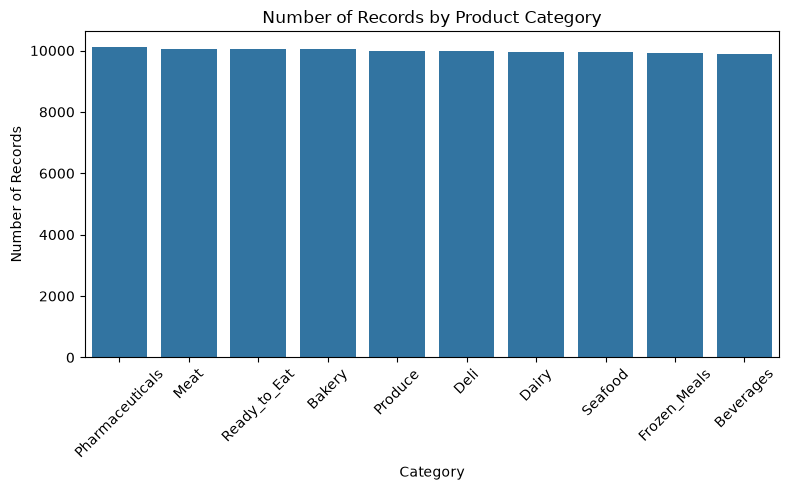

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Number of Records by Product Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

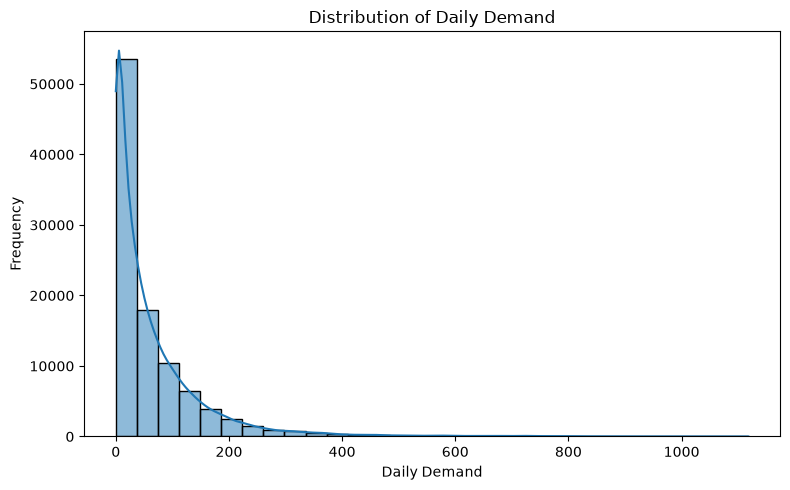

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="daily_demand",
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Demand")
plt.xlabel("Daily Demand")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

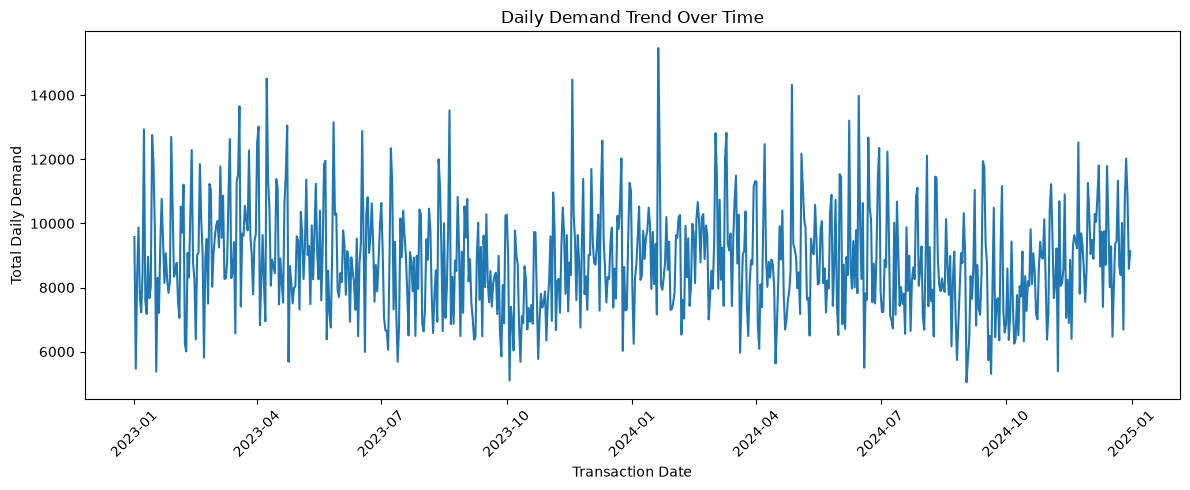

In [12]:
daily_demand = (
    df.groupby("transaction_date")["daily_demand"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_demand["transaction_date"],
    daily_demand["daily_demand"]
)

plt.title("Daily Demand Trend Over Time")
plt.xlabel("Transaction Date")
plt.ylabel("Total Daily Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

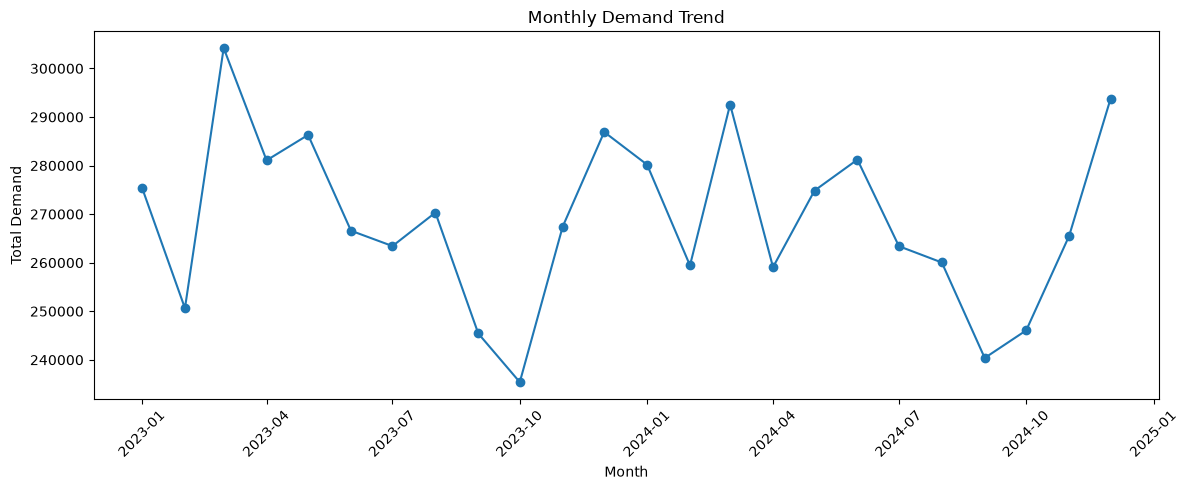

In [13]:
monthly_demand = (
    df.groupby(df["transaction_date"].dt.to_period("M"))["daily_demand"]
    .sum()
    .reset_index()
)

monthly_demand["transaction_date"] = monthly_demand["transaction_date"].dt.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_demand["transaction_date"],
    monthly_demand["daily_demand"],
    marker="o"
)

plt.title("Monthly Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



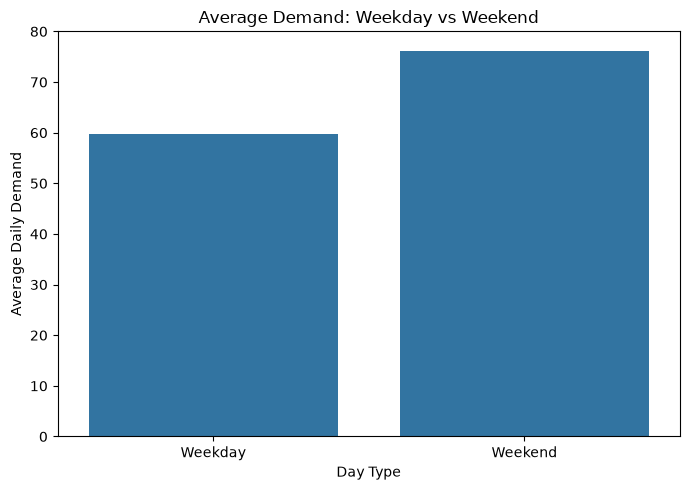

In [14]:
weekday_demand = (
    df.groupby("is_weekend")["daily_demand"]
    .mean()
    .reset_index()
)

weekday_demand["Day Type"] = weekday_demand["is_weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=weekday_demand,
    x="Day Type",
    y="daily_demand"
)

plt.title("Average Demand: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Demand")
plt.tight_layout()
plt.show()

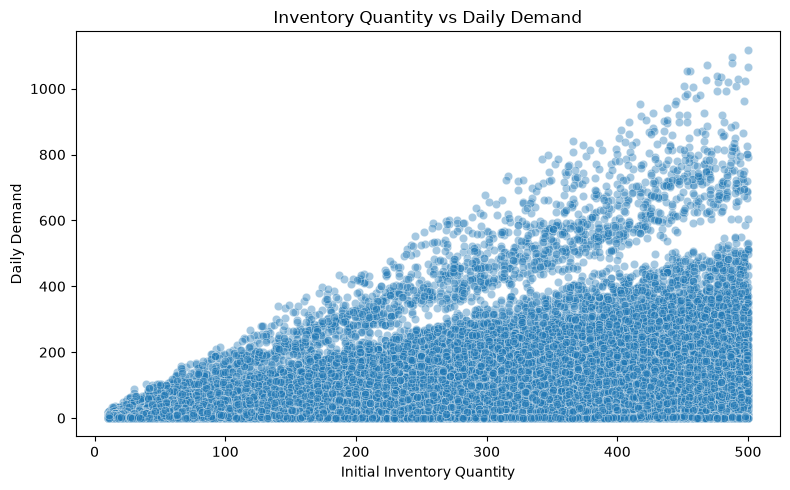

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="initial_quantity",
    y="daily_demand",
    alpha=0.4
)

plt.title("Inventory Quantity vs Daily Demand")
plt.xlabel("Initial Inventory Quantity")
plt.ylabel("Daily Demand")
plt.tight_layout()
plt.show()

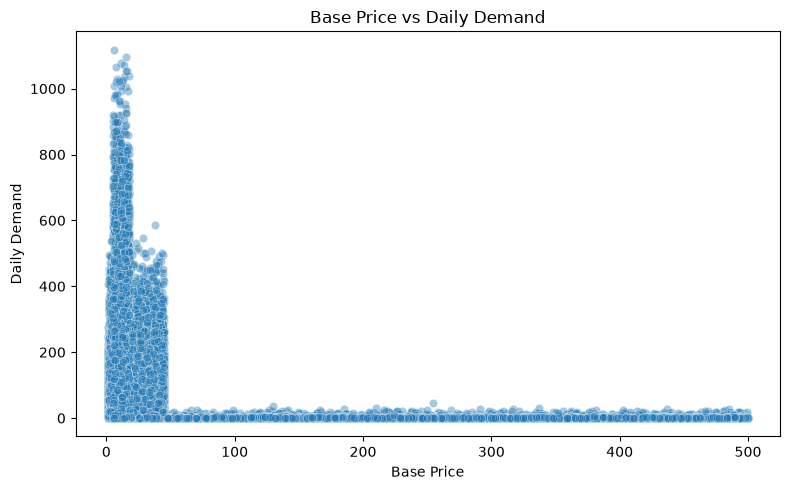

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="base_price",
    y="daily_demand",
    alpha=0.4
)

plt.title("Base Price vs Daily Demand")
plt.xlabel("Base Price")
plt.ylabel("Daily Demand")
plt.tight_layout()
plt.show()

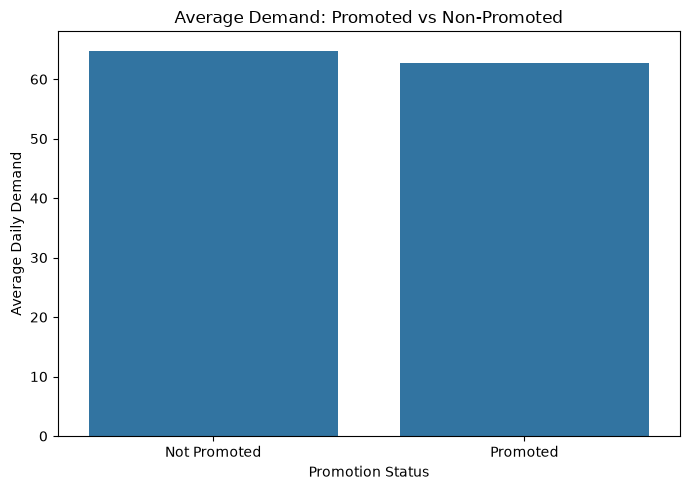

In [17]:
promotion_demand = (
    df.groupby("is_promoted")["daily_demand"]
    .mean()
    .reset_index()
)

promotion_demand["Promotion"] = promotion_demand["is_promoted"].map({
    0: "Not Promoted",
    1: "Promoted"
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=promotion_demand,
    x="Promotion",
    y="daily_demand"
)

plt.title("Average Demand: Promoted vs Non-Promoted")
plt.xlabel("Promotion Status")
plt.ylabel("Average Daily Demand")
plt.tight_layout()
plt.show()

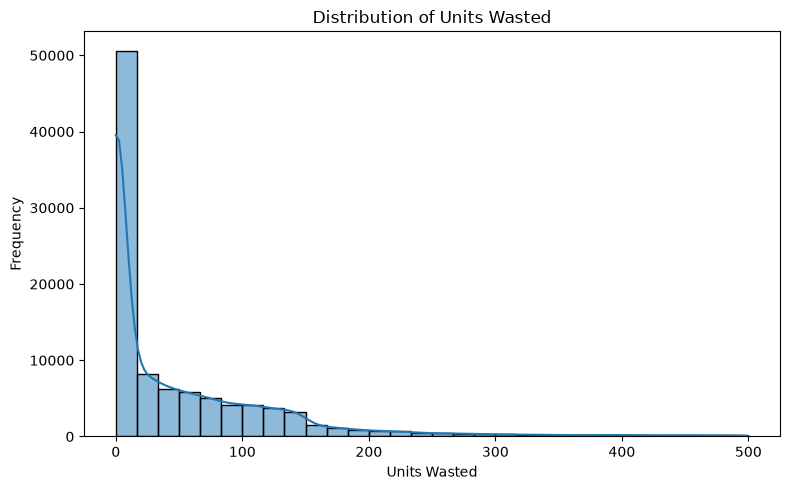

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="units_wasted",
    bins=30,
    kde=True
)

plt.title("Distribution of Units Wasted")
plt.xlabel("Units Wasted")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


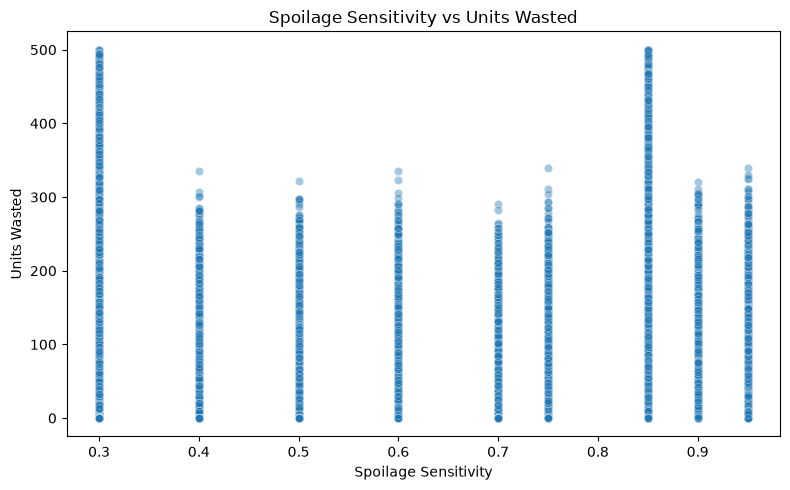

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="spoilage_sensitivity",
    y="units_wasted",
    alpha=0.4
)

plt.title("Spoilage Sensitivity vs Units Wasted")
plt.xlabel("Spoilage Sensitivity")
plt.ylabel("Units Wasted")
plt.tight_layout()
plt.show()

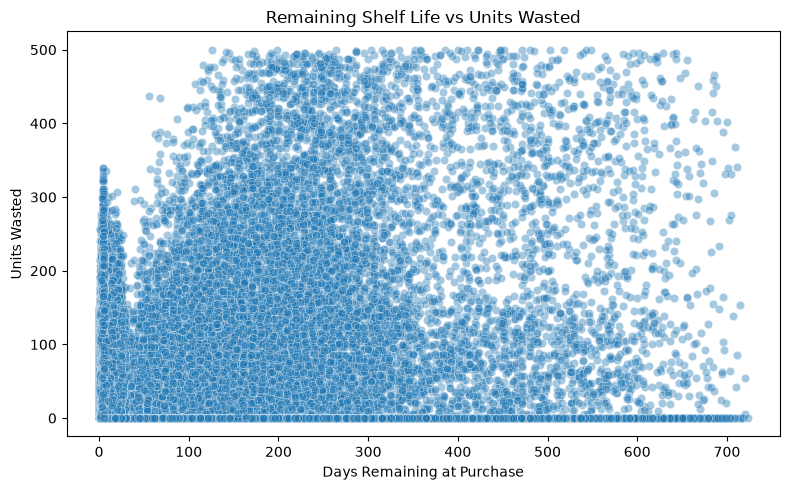

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="days_remaining_at_purchase",
    y="units_wasted",
    alpha=0.4
)

plt.title("Remaining Shelf Life vs Units Wasted")
plt.xlabel("Days Remaining at Purchase")
plt.ylabel("Units Wasted")
plt.tight_layout()
plt.show()

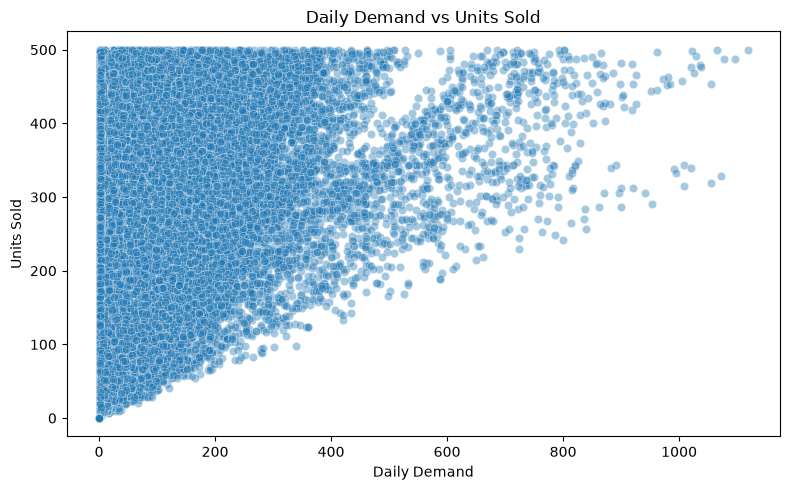

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="daily_demand",
    y="units_sold",
    alpha=0.4
)

plt.title("Daily Demand vs Units Sold")
plt.xlabel("Daily Demand")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

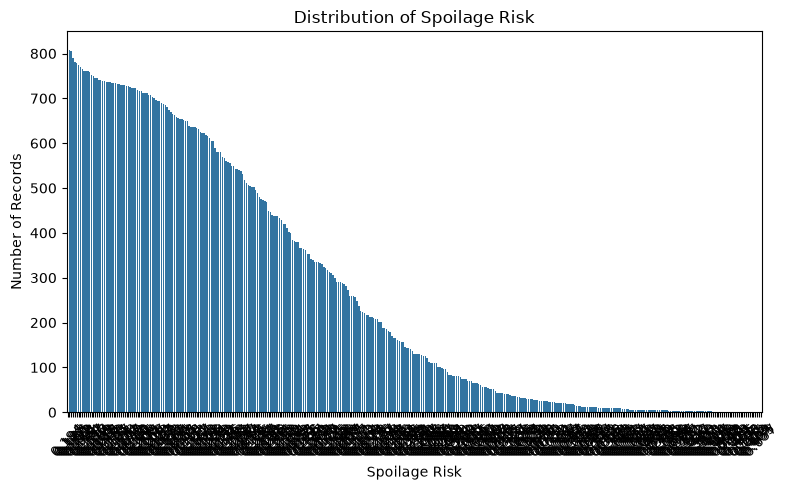

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="spoilage_risk",
    order=df["spoilage_risk"].value_counts().index
)

plt.title("Distribution of Spoilage Risk")
plt.xlabel("Spoilage Risk")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

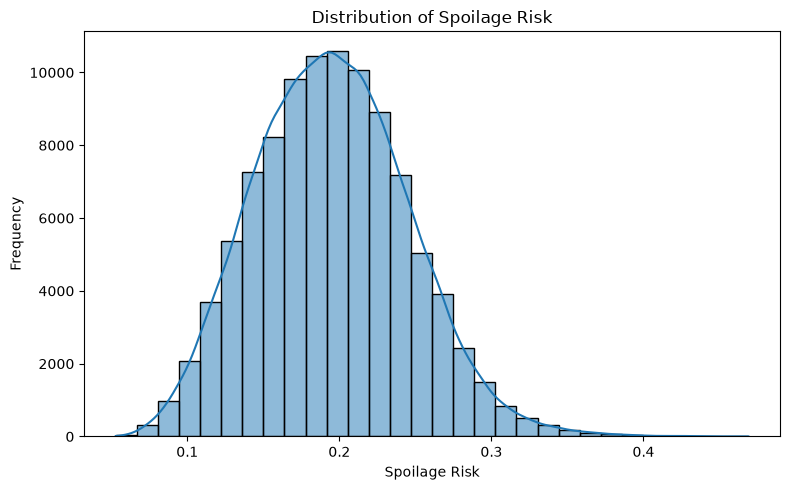

In [23]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="spoilage_risk",
    bins=30,
    kde=True
)

plt.title("Distribution of Spoilage Risk")
plt.xlabel("Spoilage Risk")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

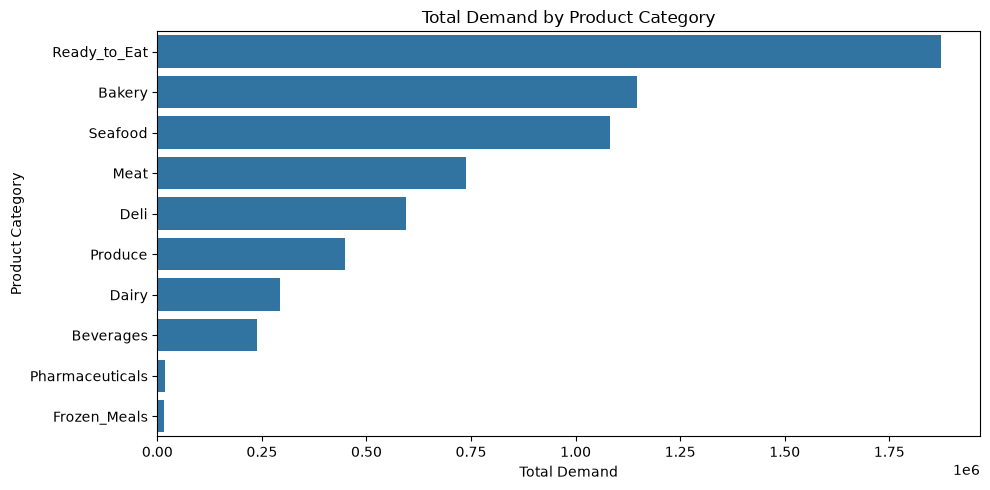

In [24]:
category_demand = (
    df.groupby("category")["daily_demand"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_demand.values,
    y=category_demand.index
)

plt.title("Total Demand by Product Category")
plt.xlabel("Total Demand")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

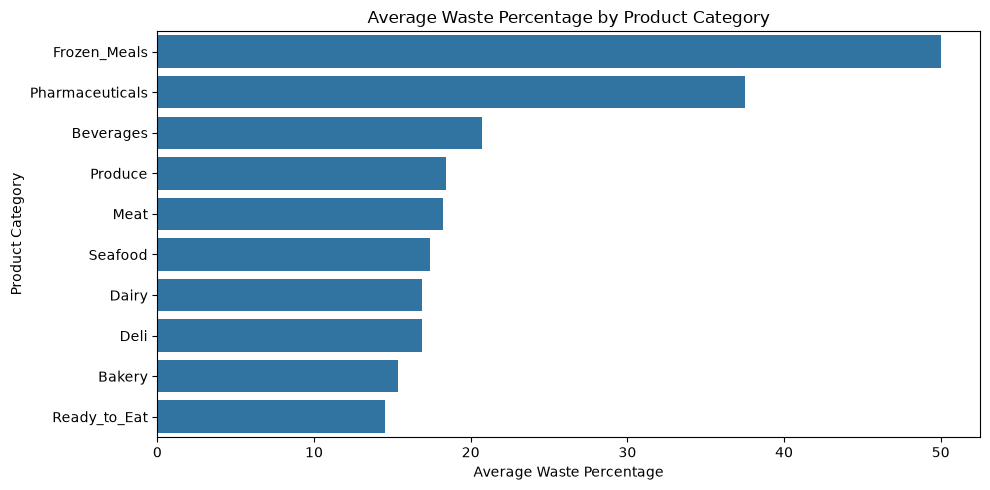

In [25]:
category_waste = (
    df.groupby("category")["waste_pct"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_waste.values,
    y=category_waste.index
)

plt.title("Average Waste Percentage by Product Category")
plt.xlabel("Average Waste Percentage")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

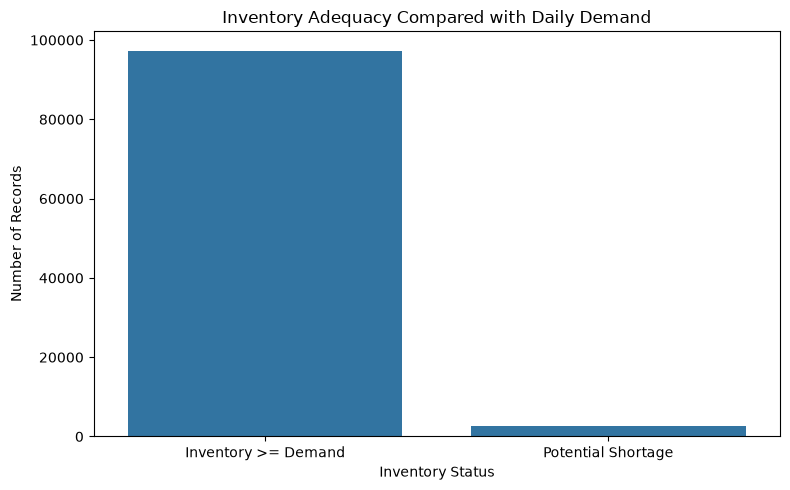

In [26]:
inventory_status = pd.DataFrame()

inventory_status["initial_quantity"] = df["initial_quantity"]
inventory_status["daily_demand"] = df["daily_demand"]

inventory_status["inventory_status"] = np.where(
    inventory_status["initial_quantity"] < inventory_status["daily_demand"],
    "Potential Shortage",
    "Inventory >= Demand"
)

status_counts = inventory_status["inventory_status"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Inventory Adequacy Compared with Daily Demand")
plt.xlabel("Inventory Status")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [27]:
shortage_count = (
    df["initial_quantity"] < df["daily_demand"]
).sum()

total_records = len(df)

shortage_percentage = (shortage_count / total_records) * 100

print("Total records:", total_records)
print("Potential shortage records:", shortage_count)
print("Potential shortage percentage:", round(shortage_percentage, 2), "%")

Total records: 100000
Potential shortage records: 2671
Potential shortage percentage: 2.67 %
